# Cottonil Sales Analysis
Analysis of the Cottonil sales, customers, branches, products, marketing and inventory data.

<div dir='rtl' style='text-align:right'>تحليل مبيعات وعملاء وفروع ومنتجات وتسويق ومخزون كوتونيل.</div>

## 1. Load the data

<div dir='rtl' style='text-align:right'>تحميل البيانات</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.max_columns = 30
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 4)

In [2]:
path = 'data/'

def read_zip(name):
    z = zipfile.ZipFile(path + name + '.zip')
    return pd.read_csv(z.open(name + '.csv'))

orders = read_zip('sales_orders')
items = pd.concat([
    pd.read_csv(path + 'sales_line_idsales_order_idorder_date.csv'),
    read_zip('sales_order_items-3'),
    read_zip('sales_order_items_4'),
]).drop_duplicates('sales_line_id')

customers = pd.read_csv(path + 'customers.csv')
branches = pd.read_csv(path + 'branches.csv')
products = pd.read_csv(path + 'products_catalog.csv')
returns = pd.read_csv(path + 'sales_returns.csv')
shipments = pd.read_csv(path + 'delivery_shipments.csv')
campaigns = pd.read_csv(path + 'marketing_campaigns.csv')
stock = pd.read_csv(path + 'monthly_stock.csv')

In [3]:
for name, df in [('orders', orders), ('items', items), ('customers', customers), ('branches', branches),
                 ('products', products), ('returns', returns), ('shipments', shipments),
                 ('campaigns', campaigns), ('stock', stock)]:
    print(name, df.shape)

orders (540000, 13)
items (1105580, 13)
customers (85000, 6)
branches (80, 7)
products (139, 6)
returns (28500, 9)
shipments (97660, 8)
campaigns (2200, 11)
stock (142784, 7)


## 2. Data cleaning

<div dir='rtl' style='text-align:right'>تنظيف البيانات</div>

In [4]:
orders['order_date'] = pd.to_datetime(orders['order_date'])
items['order_date'] = pd.to_datetime(items['order_date'])
returns['return_date'] = pd.to_datetime(returns['return_date'])
shipments['ship_date'] = pd.to_datetime(shipments['ship_date'])
shipments['delivery_date'] = pd.to_datetime(shipments['delivery_date'])
branches['opening_date'] = pd.to_datetime(branches['opening_date'])
customers['joined_date'] = pd.to_datetime(customers['joined_date'])

orders['year'] = orders['order_date'].dt.year
orders['month'] = orders['order_date'].dt.month
orders['weekday'] = orders['order_date'].dt.day_name()
items['year'] = items['order_date'].dt.year

In [5]:
print(orders.isna().sum()[orders.isna().sum() > 0])
print('duplicate orders:', orders.sales_order_id.duplicated().sum())
print('duplicate lines:', items.sales_line_id.duplicated().sum())
print(orders.order_date.min().date(), 'to', orders.order_date.max().date())

customer_id    102961
dtype: int64
duplicate orders: 0


duplicate lines: 0
2018-10-19 to 2026-10-18


In [6]:
orders.describe()

,order_date,items_count,gross_EGP,discount_EGP,net_before_tax_EGP,tax_EGP,paid_total_EGP,year,month
count,540000,"540,000.00","540,000.00","540,000.00","540,000.00","540,000.00","540,000.00","540,000.00","540,000.00"
mean,2023-06-17 07:45:16.639999,2.11,"1,628.14",70.23,"1,557.92",218.11,"1,776.02","2,022.96",6.56
min,2018-10-19 00:00:00,1.00,12.99,0.00,11.69,1.64,13.33,"2,018.00",1.00
25%,2021-09-11 00:00:00,1.00,299.94,0.00,286.58,40.12,326.70,"2,021.00",4.00
50%,2023-10-22 00:00:00,2.00,703.30,18.06,672.59,94.16,766.75,"2,023.00",6.00
75%,2025-05-24 00:00:00,3.00,"1,654.63",60.67,"1,583.88",221.74,"1,805.62","2,025.00",10.00
max,2026-10-18 00:00:00,5.00,"244,799.34","48,794.94","210,446.07","29,462.45","239,908.52","2,026.00",12.00
std,NaN,1.01,"3,568.67",234.34,"3,417.24",478.41,"3,895.66",2.27,3.47


## 3. Sales overview

<div dir='rtl' style='text-align:right'>نظرة عامة على المبيعات</div>

In [7]:
print('Revenue (EGP):', round(orders.net_before_tax_EGP.sum()))
print('Orders:', len(orders))
print('Average order value:', round(orders.net_before_tax_EGP.mean()))
print('Discount % of gross:', round(orders.discount_EGP.sum() / orders.gross_EGP.sum() * 100, 1))
print('Gross margin %:', round(items.margin_EGP.sum() / items.net_line_EGP.sum() * 100, 1))

Revenue (EGP): 841274176
Orders: 540000
Average order value: 1558
Discount % of gross: 4.3
Gross margin %: 38.3


In [8]:
yearly = orders.groupby('year').agg(orders=('sales_order_id', 'count'), revenue=('net_before_tax_EGP', 'sum'))
yearly['avg_order_value'] = yearly.revenue / yearly.orders
yearly['revenue_growth_%'] = yearly.revenue.pct_change() * 100
yearly['orders_growth_%'] = yearly.orders.pct_change() * 100
yearly

,orders,revenue,avg_order_value,revenue_growth_%,orders_growth_%
year,,,,,
2018,8576,"3,734,869.34",435.50,NaN,NaN
2019,44108,"21,620,204.92",490.17,478.87,414.32
2020,46425,"25,709,342.33",553.78,18.91,5.25
2021,53269,"32,716,862.22",614.18,27.26,14.74
2022,61934,"51,578,474.33",832.80,57.65,16.27
2023,72233,"84,147,934.73","1,164.95",63.15,16.63
2024,81885,"148,782,350.27","1,816.97",76.81,13.36
2025,93384,"234,138,548.44","2,507.27",57.37,14.04
2026,78186,"238,845,589.74","3,054.84",2.01,-16.27


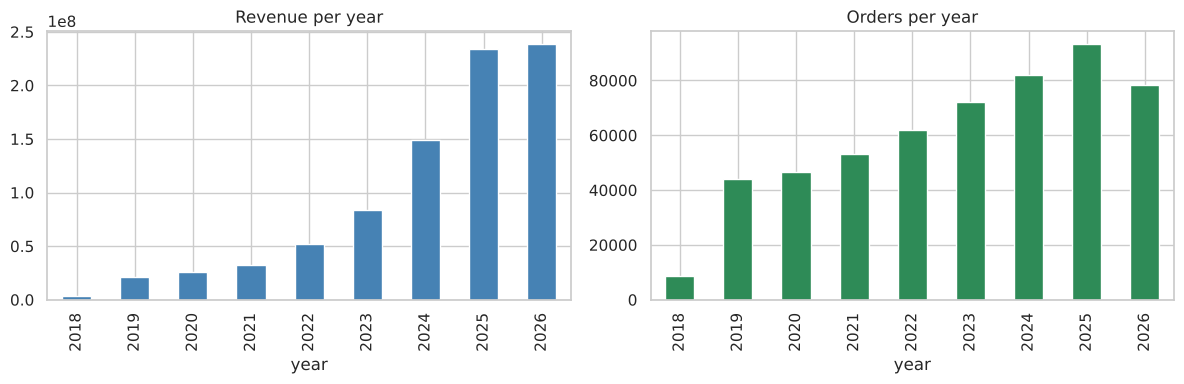

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
yearly.revenue.plot.bar(ax=ax[0], color='steelblue', title='Revenue per year')
yearly.orders.plot.bar(ax=ax[1], color='seagreen', title='Orders per year')
plt.tight_layout()

<Axes: title={'center': 'Monthly revenue'}, xlabel='order_date'>

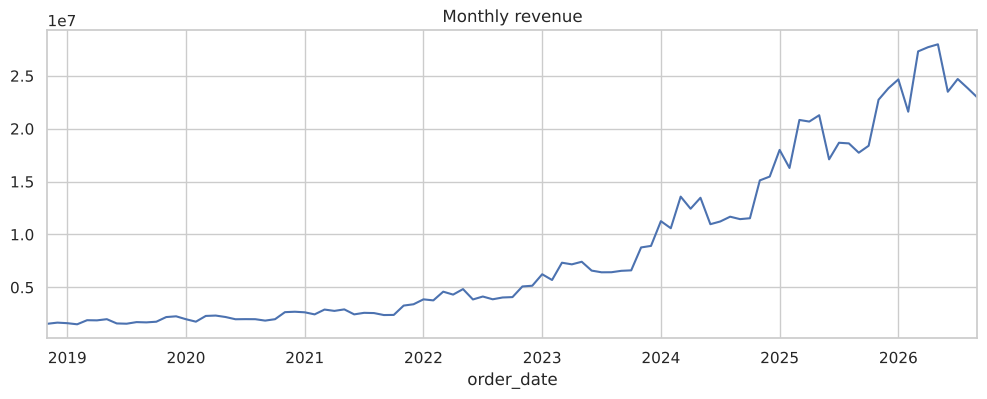

In [10]:
monthly = orders.groupby(orders.order_date.dt.to_period('M')).agg(revenue=('net_before_tax_EGP', 'sum'), orders=('sales_order_id', 'count'))
monthly = monthly.iloc[1:-1]
monthly.revenue.plot(title='Monthly revenue', figsize=(12, 4))

<Axes: title={'center': 'Average order value per year'}, xlabel='year'>

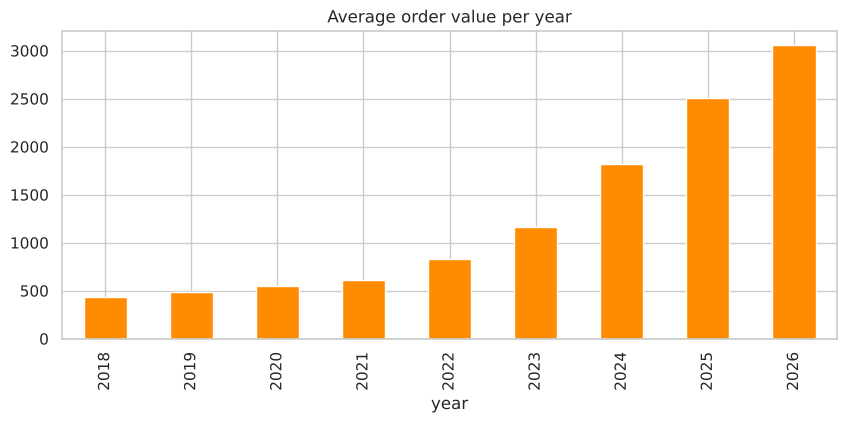

In [11]:
yearly['avg_order_value'].plot.bar(title='Average order value per year', color='darkorange')

## 4. Seasonality

<div dir='rtl' style='text-align:right'>المواسم</div>

Text(0.5, 1.0, 'Orders by month (1.00 = average month)')

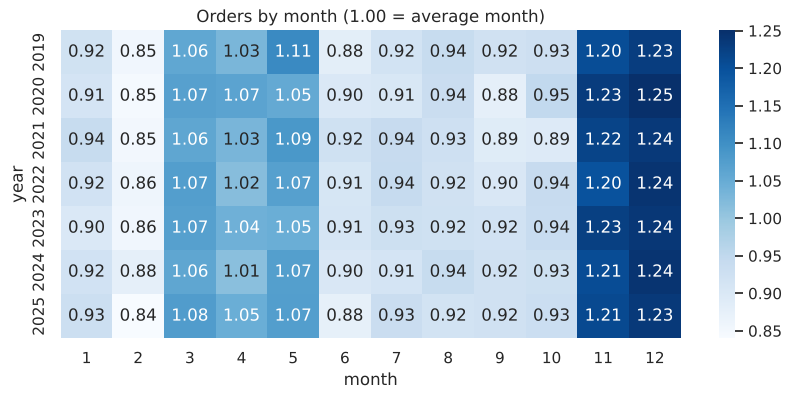

In [12]:
full = orders[(orders.year >= 2019) & (orders.year <= 2025)]
by_month = full.groupby(['year', 'month']).size().unstack()
by_month = by_month.div(by_month.mean(axis=1), axis=0)
sns.heatmap(by_month, annot=True, fmt='.2f', cmap='Blues')
plt.title('Orders by month (1.00 = average month)')

<Axes: title={'center': 'Orders by weekday'}, xlabel='weekday'>

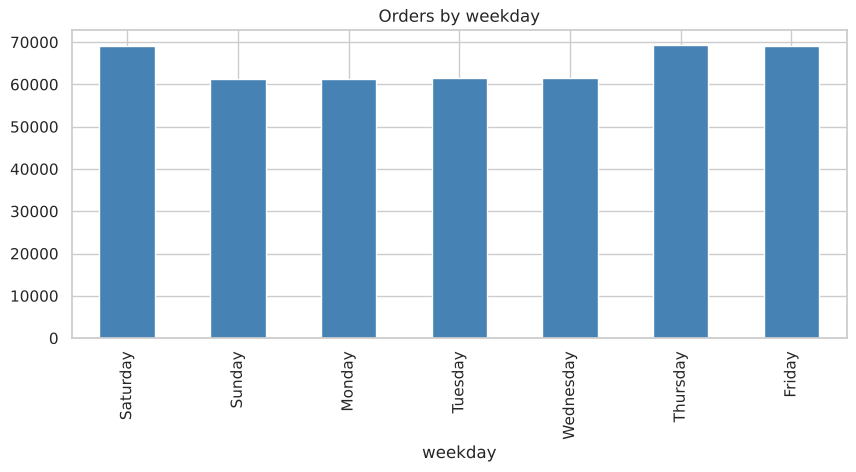

In [13]:
order_days = ['Saturday', 'Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
full.groupby('weekday').size().reindex(order_days).plot.bar(title='Orders by weekday', color='steelblue')

## 5. Sales channels and payment

<div dir='rtl' style='text-align:right'>القنوات والدفع</div>

In [14]:
channels = orders.groupby('sales_channel').agg(orders=('sales_order_id', 'count'), revenue=('net_before_tax_EGP', 'sum'), avg_order=('net_before_tax_EGP', 'mean'))
channels['orders_%'] = channels.orders / channels.orders.sum() * 100
channels['revenue_%'] = channels.revenue / channels.revenue.sum() * 100
channels

,orders,revenue,avg_order,orders_%,revenue_%
sales_channel,,,,,
E-commerce,97660,"105,408,084.94","1,079.34",18.09,12.53
Retail POS,388171,"416,226,955.60","1,072.28",71.88,49.48
Wholesale / reseller,54169,"319,639,135.78","5,900.78",10.03,37.99


<Axes: title={'center': 'Share of revenue'}>

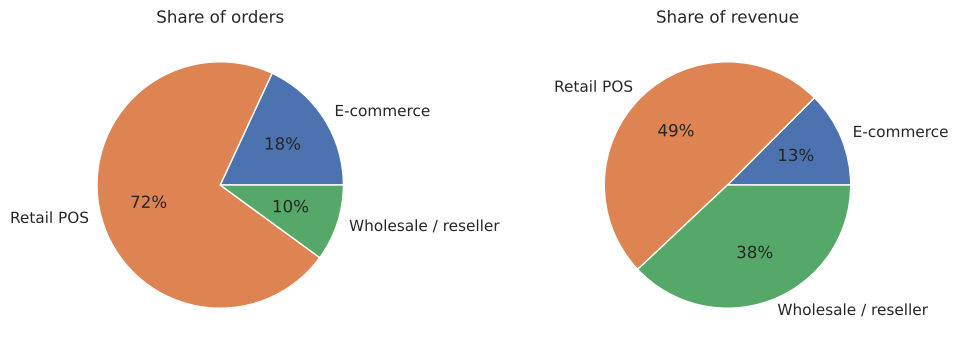

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
channels['orders_%'].plot.pie(ax=ax[0], autopct='%.0f%%', title='Share of orders', ylabel='')
channels['revenue_%'].plot.pie(ax=ax[1], autopct='%.0f%%', title='Share of revenue', ylabel='')

In [16]:
pd.crosstab(orders.sales_channel, orders.payment_method, normalize='index').mul(100).round(1)

payment_method,Bank transfer,Card POS,Cash,Cash on delivery,Wallet
sales_channel,,,,,
E-commerce,7.00,33.90,40.10,8.00,11.00
Retail POS,7.10,33.90,39.90,8.10,11.10
Wholesale / reseller,7.00,34.10,39.80,8.10,11.00


## 6. Branches

<div dir='rtl' style='text-align:right'>الفروع</div>

In [17]:
orders_b = orders.merge(branches, on='branch_id')
branch_sales = orders_b.groupby(['branch_id', 'branch_name_ar', 'governorate_ar', 'retail_location_type']).agg(
    orders=('sales_order_id', 'count'), revenue=('net_before_tax_EGP', 'sum')).reset_index()
branch_sales = branch_sales.sort_values('revenue', ascending=False)
branch_sales.head(10)

,branch_id,branch_name_ar,governorate_ar,retail_location_type,orders,revenue
2,BR003,القطامية داون تاون,القاهرة,Retail branch,6932,"11,434,150.99"
73,BR074,نجع حمادي,قنا,Retail branch,6893,"11,274,021.44"
14,BR015,مدينتي الربيع,القاهرة,Retail branch,6881,"11,244,325.21"
48,BR049,القومية,الشرقية,Retail branch,6787,"11,011,002.02"
26,BR027,إمبابة,الجيزة,Retail branch,6859,"10,935,666.88"
29,BR030,جليم,الإسكندرية,Retail branch,6741,"10,931,944.09"
22,BR023,فيصل,الجيزة,Retail branch,6633,"10,903,469.25"
46,BR047,شبراخيت,البحيرة,Retail branch,6878,"10,902,863.28"
9,BR010,روكسي,القاهرة,Point of sale / reseller,6835,"10,893,340.36"
64,BR065,ميدان الساعة,المنيا,Retail branch,6703,"10,849,999.01"


In [18]:
branch_sales.tail(10)

,branch_id,branch_name_ar,governorate_ar,retail_location_type,orders,revenue
47,BR048,مارينا 2,مطروح,Retail branch,6640,"10,157,998.92"
69,BR070,مول الصفوة,دمياط,Retail branch,6721,"10,149,980.13"
4,BR005,المعادي جراند مول,القاهرة,Retail branch,6647,"10,117,641.95"
52,BR053,سمنود,الغربية,Retail branch,6729,"10,108,093.94"
66,BR067,بني سويف الجديدة,بني سويف,Retail branch,6581,"10,107,400.31"
1,BR002,السيدة زينب,القاهرة,Point of sale / reseller,6800,"10,057,326.94"
28,BR029,الهانوفيل,الإسكندرية,Point of sale / reseller,6648,"10,036,423.76"
20,BR021,العتبة,القاهرة,Point of sale / reseller,6638,"9,939,578.39"
40,BR041,طلخا,الدقهلية,Retail branch,6766,"9,922,760.90"
35,BR036,سان ستيفانو,الإسكندرية,Retail branch,6753,"9,844,120.95"


Best branch / worst branch revenue: 1.16


<Axes: title={'center': 'Distribution of branch revenue'}, ylabel='Frequency'>

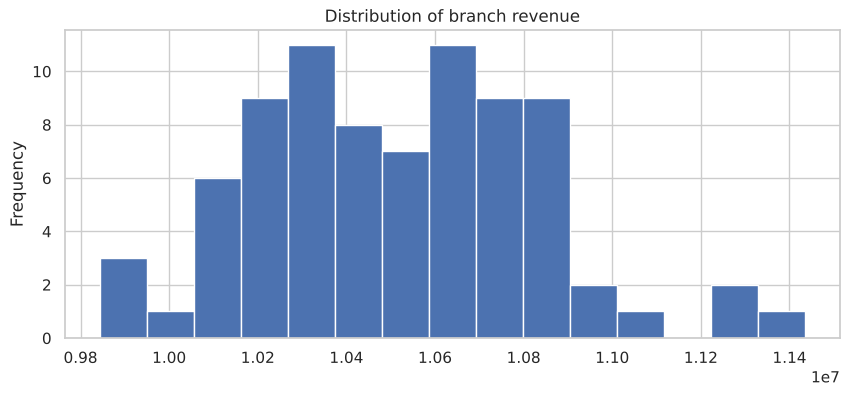

In [19]:
print('Best branch / worst branch revenue:', round(branch_sales.revenue.max() / branch_sales.revenue.min(), 2))
branch_sales.revenue.plot.hist(bins=15, title='Distribution of branch revenue')

In [20]:
gov = branch_sales.groupby('governorate_ar').agg(branches=('branch_id', 'count'), revenue=('revenue', 'sum'))
gov['revenue_per_branch'] = gov.revenue / gov.branches
gov.sort_values('revenue', ascending=False).head(10)

,branches,revenue,revenue_per_branch
governorate_ar,,,
القاهرة,21,"221,368,509.72","10,541,357.61"
الإسكندرية,10,"104,644,335.42","10,464,433.54"
الجيزة,6,"64,357,966.28","10,726,327.71"
المنيا,4,"42,551,070.85","10,637,767.71"
البحيرة,4,"41,851,559.27","10,462,889.82"
الغربية,4,"41,492,878.96","10,373,219.74"
الدقهلية,4,"40,975,387.51","10,243,846.88"
الشرقية,3,"32,480,233.30","10,826,744.43"
المنوفية,3,"31,251,465.44","10,417,155.15"


In [21]:
branch_type = branch_sales.groupby('retail_location_type').agg(branches=('branch_id', 'count'), revenue=('revenue', 'sum'))
branch_type['revenue_per_branch'] = branch_type.revenue / branch_type.branches
branch_type

,branches,revenue,revenue_per_branch
retail_location_type,,,
Point of sale / reseller,28,"293,503,444.65","10,482,265.88"
Retail branch,52,"547,770,731.67","10,534,052.53"


In [22]:
first_sale = orders.groupby('branch_id').order_date.min().rename('first_sale')
check = branches.set_index('branch_id').join(first_sale)
check['days_sold_before_opening'] = (check.opening_date - check.first_sale).dt.days
print((check.days_sold_before_opening > 0).sum(), 'of', len(check), 'branches have sales before their opening date')
check.days_sold_before_opening.describe()

80 of 80 branches have sales before their opening date


count    80.00
mean    317.09
std     190.92
min      17.00
25%     190.25
50%     302.50
75%     460.50
max     680.00
Name: days_sold_before_opening, dtype: float64

## 7. Products and categories

<div dir='rtl' style='text-align:right'>المنتجات والفئات</div>

In [23]:
lines = items.merge(products[['product_id', 'product_name_ar', 'category_en', 'audience']], on='product_id', how='left')
cat = lines.groupby('category_en').agg(revenue=('net_line_EGP', 'sum'), units=('quantity', 'sum'), margin=('margin_EGP', 'sum'))
cat['revenue_%'] = cat.revenue / cat.revenue.sum() * 100
cat['margin_%'] = cat.margin / cat.revenue * 100
cat.sort_values('revenue', ascending=False)

,revenue,units,margin,revenue_%,margin_%
category_en,,,,,
Men boxers,"192,485,784.18",371152,"73,545,020.17",23.09,38.21
Men tops,"163,001,549.31",429902,"62,619,761.50",19.55,38.42
Socks,"115,151,672.61",885526,"44,213,469.42",13.81,38.40
Men underwear,"52,590,043.53",183826,"20,230,984.98",6.31,38.47
Women pajamas,"49,775,999.88",75886,"19,079,509.95",5.97,38.33
Women tops,"48,119,322.00",330432,"18,462,260.71",5.77,38.37
Girls pajamas,"38,620,215.03",154431,"14,830,174.90",4.63,38.40
Boys pajamas,"37,823,195.06",152262,"14,525,155.29",4.54,38.40
Home textiles,"33,344,207.82",95982,"12,714,639.76",4.00,38.13


<Axes: title={'center': 'Revenue by category'}, ylabel='category_en'>

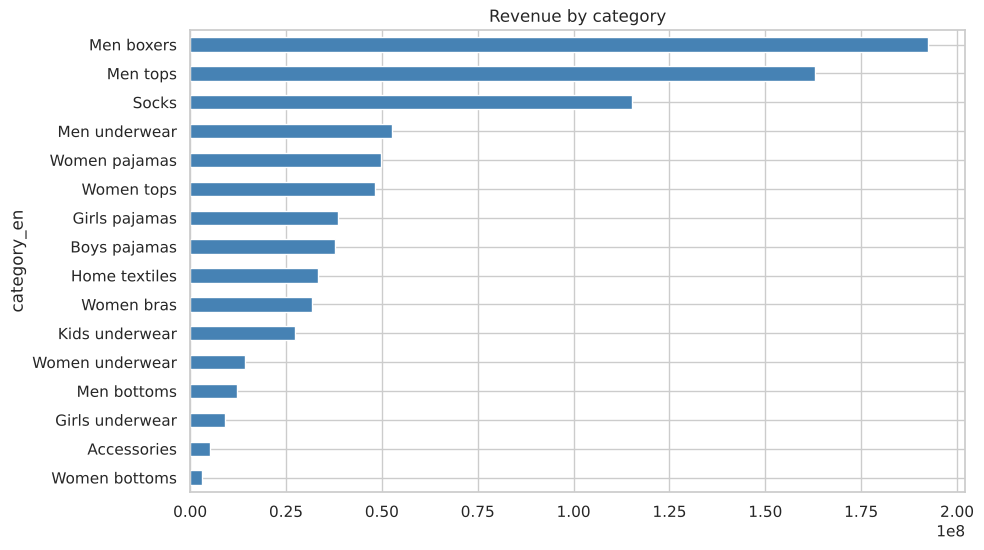

In [24]:
cat.revenue.sort_values().plot.barh(title='Revenue by category', color='steelblue', figsize=(10, 6))

In [25]:
top_products = lines.groupby(['product_id', 'product_name_ar', 'category_en']).agg(revenue=('net_line_EGP', 'sum'), units=('quantity', 'sum')).sort_values('revenue', ascending=False)
top_products.head(10)

,,,revenue,units
product_id,product_name_ar,category_en,,
PR0060,3 قطع بوكسر رجالى مارسريزيه,Men boxers,"62,500,969.85",54562
PR0090,8 قطع بوكسر CN,Men boxers,"38,153,949.72",52120
PR0121,تيشيرت مرسريزيه,Men tops,"30,412,860.09",46820
PR0081,4 اندرشيرت كم استريتش,Men tops,"27,741,278.51",48415
PR0085,5 قطع بوكسر كاجوال,Men boxers,"26,858,790.44",51215
PR0122,بيجامة شتوي حريمي كود 2031,Women pajamas,"25,072,180.88",37819
PR0123,بيجامة شتوي حريمي كود 2032,Women pajamas,"24,703,819.00",38067
PR0137,تيشيرت مرسريزيه الوان ( رمادي - اسود - ذهبي- ابيض ),Men tops,"23,074,846.24",47445
PR0086,6 قطع بوكسر ديجيتال,Men boxers,"22,151,323.34",52935


In [26]:
top_products['cum_%'] = top_products.revenue.cumsum() / top_products.revenue.sum() * 100
print('Products making 80% of revenue:', (top_products['cum_%'] <= 80).sum(), 'of', len(top_products))

Products making 80% of revenue: 47 of 139


In [27]:
audience = lines.groupby('audience').agg(revenue=('net_line_EGP', 'sum'), units=('quantity', 'sum'))
audience['revenue_%'] = audience.revenue / audience.revenue.sum() * 100
audience

,revenue,units,revenue_%
audience,,,
Boys,"37,823,195.06",152262,4.54
Girls,"38,620,215.03",154431,4.63
Kids,"27,287,489.29",286840,3.27
Men,"242,556,568.22",1003328,29.09
Unisex,"416,665,419.23",1416018,49.98
Women,"70,757,523.21",288201,8.49


## 8. Prices and discounts

<div dir='rtl' style='text-align:right'>الأسعار والخصومات</div>

In [28]:
lines['discount_%'] = lines.discount_line_EGP / lines.gross_line_EGP * 100
lines['discount_band'] = pd.cut(lines['discount_%'], [-0.1, 0, 2, 5, 10, 15, 100], labels=['0', '0-2', '2-5', '5-10', '10-15', '15+'])
bands = lines.groupby('discount_band', observed=True).agg(lines=('sales_line_id', 'count'), avg_quantity=('quantity', 'mean'), revenue=('net_line_EGP', 'sum'), margin=('margin_EGP', 'sum'))
bands['margin_%'] = bands.margin / bands.revenue * 100
bands

,lines,avg_quantity,revenue,margin,margin_%
discount_band,,,,,
0,508776,2.98,"401,168,538.18","164,588,295.23",41.03
2-5,230374,3.06,"178,352,302.80","68,777,509.83",38.56
5-10,182967,3.03,"134,587,797.88","48,509,247.77",36.04
10-15,120875,2.86,"79,875,523.44","26,208,808.56",32.81
15+,62588,2.86,"39,726,247.74","11,589,452.32",29.17


In [29]:
lines_ch = lines.merge(orders[['sales_order_id', 'sales_channel']], on='sales_order_id')
lines_ch.groupby('sales_channel').agg(avg_quantity=('quantity', 'mean'), discount_=('discount_line_EGP', 'sum'), gross=('gross_line_EGP', 'sum')).assign(discount_pct=lambda d: d.discount_ / d.gross * 100)

,avg_quantity,discount_,gross,discount_pct
sales_channel,,,,
E-commerce,2.06,"4,696,456.38","109,187,626.08",4.30
Retail POS,2.05,"18,540,509.02","430,964,265.27",4.30
Wholesale / reseller,11.34,"14,342,807.40","331,138,291.49",4.33


In [30]:
print(lines[['discount_%', 'quantity']].corr(method='spearman'))

            discount_%  quantity
discount_%        1.00     -0.00
quantity         -0.00      1.00


In [31]:
price_by_year = orders.groupby('year').agg(avg_order=('net_before_tax_EGP', 'mean'))
price_by_year['avg_unit_price'] = lines.groupby('year').unit_price_EGP.mean()
price_by_year['change_%'] = price_by_year.avg_unit_price.pct_change() * 100
price_by_year

,avg_order,avg_unit_price,change_%
year,,,
2018,435.50,71.54,NaN
2019,490.17,81.01,13.24
2020,553.78,91.42,12.85
2021,614.18,101.34,10.84
2022,832.80,137.21,35.40
2023,"1,164.95",193.32,40.89
2024,"1,816.97",300.68,55.54
2025,"2,507.27",416.13,38.40
2026,"3,054.84",508.83,22.28


## 9. Customers

<div dir='rtl' style='text-align:right'>العملاء</div>

In [32]:
print('Guest orders %:', round(orders.customer_id.isna().mean() * 100, 1))
print('Registered customers:', len(customers), '- bought at least once:', orders.customer_id.nunique())

Guest orders %: 19.1
Registered customers: 85000 - bought at least once: 74660


Repeat customers %: 86.8
Inactive for more than 365 days %: 30.9


<Axes: title={'center': 'Customers by number of orders'}, xlabel='orders'>

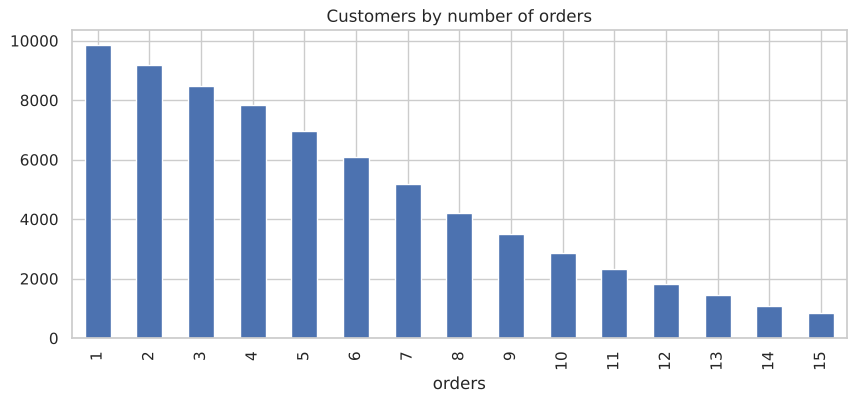

In [33]:
buyers = orders.dropna(subset=['customer_id']).groupby('customer_id').agg(orders=('sales_order_id', 'count'), revenue=('net_before_tax_EGP', 'sum'), last_order=('order_date', 'max'))
buyers['days_since_last_order'] = (orders.order_date.max() - buyers.last_order).dt.days
print('Repeat customers %:', round((buyers.orders >= 2).mean() * 100, 1))
print('Inactive for more than 365 days %:', round((buyers.days_since_last_order > 365).mean() * 100, 1))
buyers.orders.value_counts().sort_index().head(15).plot.bar(title='Customers by number of orders')

In [34]:
cust_seg = orders.merge(customers[['customer_id', 'customer_segment', 'age_band']], on='customer_id')
seg = cust_seg.groupby('customer_segment').agg(customers=('customer_id', 'nunique'), orders=('sales_order_id', 'count'), revenue=('net_before_tax_EGP', 'sum'))
seg['revenue_per_customer'] = seg.revenue / seg.customers
seg

,customers,orders,revenue,revenue_per_customer
customer_segment,,,,
B2B reseller,1476,8587,"13,224,071.82","8,959.40"
Retail,73184,428452,"667,097,086.99","9,115.34"


In [35]:
age = cust_seg.groupby('age_band').agg(customers=('customer_id', 'nunique'), revenue=('net_before_tax_EGP', 'sum'))
age['revenue_per_customer'] = age.revenue / age.customers
age

,customers,revenue,revenue_per_customer
age_band,,,
18-24,14933,"138,554,196.46","9,278.39"
25-34,14949,"136,870,116.95","9,155.80"
35-44,14800,"133,210,427.86","9,000.70"
45-54,14935,"135,693,273.59","9,085.59"
55+,15043,"135,993,143.95","9,040.29"


In [36]:
top10 = buyers.revenue.sort_values(ascending=False)
print('Top 10% of customers share of revenue %:', round(top10.head(int(len(top10) * 0.1)).sum() / top10.sum() * 100, 1))

Top 10% of customers share of revenue %: 32.8


## 10. Returns

<div dir='rtl' style='text-align:right'>المرتجعات</div>

Return records: 28500
Return rate (% of sold lines): 2.6
Refunds / revenue %: 1.7


<Axes: title={'center': 'Return reasons'}, xlabel='reason'>

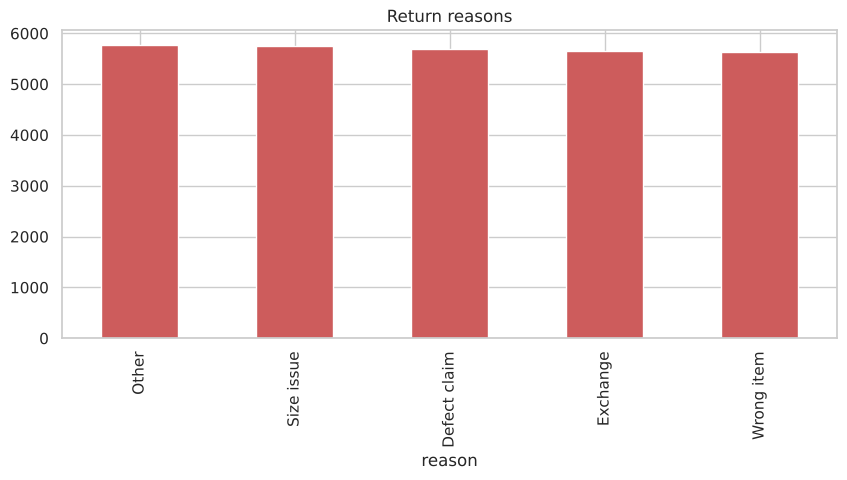

In [37]:
print('Return records:', len(returns))
print('Return rate (% of sold lines):', round(len(returns) / len(items) * 100, 1))
print('Refunds / revenue %:', round(returns.refund_amount_EGP.sum() / items.net_line_EGP.sum() * 100, 1))
returns.reason.value_counts().plot.bar(title='Return reasons', color='indianred')

<Axes: title={'center': 'Return rate by category (%)'}, ylabel='category_en'>

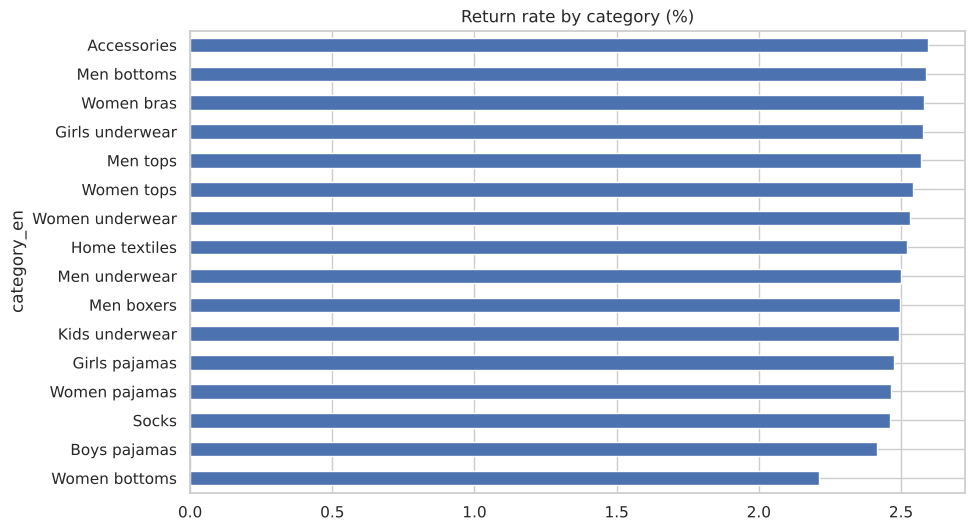

In [38]:
ret = returns.merge(lines[['sales_line_id', 'category_en', 'net_line_EGP', 'quantity']], on='sales_line_id')
rc = ret.groupby('category_en').size() / lines.groupby('category_en').size() * 100
rc.sort_values().plot.barh(title='Return rate by category (%)', figsize=(10, 6))

In [39]:
print('Refunds higher than the value of the sold line:', (ret.refund_amount_EGP > ret.net_line_EGP + 0.01).sum())

Refunds higher than the value of the sold line: 5508


## 11. Delivery

<div dir='rtl' style='text-align:right'>التوصيل</div>

fulfillment_status
Delivered    94705
Delayed       2955
Name: count, dtype: int64


<Axes: title={'center': 'Delivery days'}, xlabel='delivery_days'>

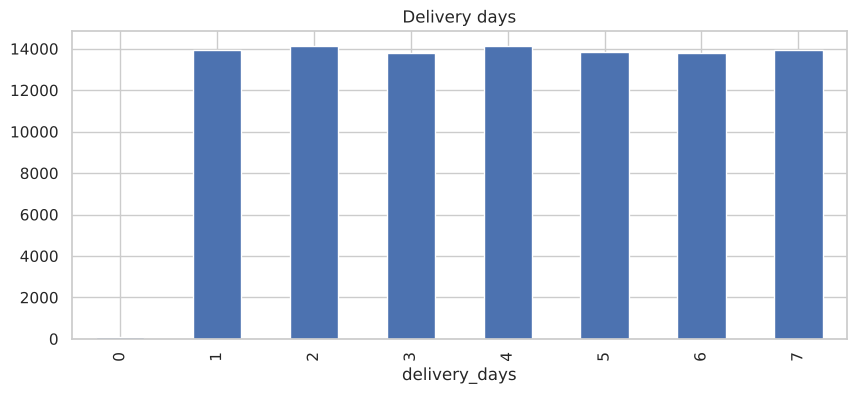

In [40]:
shipments['delivery_days'] = (shipments.delivery_date - shipments.ship_date).dt.days
print(shipments.fulfillment_status.value_counts())
shipments.delivery_days.value_counts().sort_index().plot.bar(title='Delivery days')

In [41]:
shipments.groupby('carrier').agg(shipments=('shipment_id', 'count'), avg_days=('delivery_days', 'mean'), avg_fee=('shipping_fee_EGP', 'mean'))

,shipments,avg_days,avg_fee
carrier,,,
Express carrier,32442,3.99,51.10
In-house delivery,32641,3.99,51.40
Local courier,32577,3.98,51.51


In [42]:
shipments.groupby('fulfillment_status').delivery_days.mean()

fulfillment_status
Delayed     3.96
Delivered   3.99
Name: delivery_days, dtype: float64

## 12. Marketing

<div dir='rtl' style='text-align:right'>التسويق</div>

In [43]:
mk = campaigns.groupby('channel').agg(campaigns=('campaign_id', 'count'), spend=('spend_EGP', 'sum'), clicks=('clicks', 'sum'), impressions=('impressions', 'sum'), orders=('orders_attributed', 'sum'))
mk['cost_per_order'] = mk.spend / mk.orders
mk['click_rate_%'] = mk.clicks / mk.impressions * 100
mk

,campaigns,spend,clicks,impressions,orders,cost_per_order,click_rate_%
channel,,,,,,,
Google Ads,382,"37,775,005.23",82820905,1900645796,4035521,9.36,4.36
In-store,363,"36,216,859.28",84450875,1843934547,4303403,8.42,4.58
Influencers,373,"35,383,373.45",71115857,1680740255,3718093,9.52,4.23
Meta Ads,387,"38,629,995.58",91205061,1950913966,4603025,8.39,4.67
Outdoor,367,"37,588,539.69",79864762,1780808952,3767602,9.98,4.48
SMS / CRM,328,"33,915,346.54",70152587,1595266929,3679103,9.22,4.40


In [44]:
print('Total spend (EGP):', round(campaigns.spend_EGP.sum()))
print('Orders claimed by campaigns:', campaigns.orders_attributed.sum())
print('Real orders in the data:', len(orders))

Total spend (EGP): 219509120
Orders claimed by campaigns: 24106747
Real orders in the data: 540000


In [45]:
spend_year = campaigns.groupby(campaigns.start_date.str[:4].astype(int)).spend_EGP.sum()
rev_year = orders.groupby('year').net_before_tax_EGP.sum()
compare = pd.DataFrame({'spend': spend_year, 'revenue': rev_year})
compare['spend_%_of_revenue'] = compare.spend / compare.revenue * 100
compare

,spend,revenue,spend_%_of_revenue
2018,"4,586,169.77","3,734,869.34",122.79
2019,"24,587,748.94","21,620,204.92",113.73
2020,"23,639,949.90","25,709,342.33",91.95
2021,"28,257,678.76","32,716,862.22",86.37
2022,"30,220,482.30","51,578,474.33",58.59
2023,"29,028,771.79","84,147,934.73",34.50
2024,"25,719,461.50","148,782,350.27",17.29
2025,"30,238,992.83","234,138,548.44",12.91
2026,"23,229,863.98","238,845,589.74",9.73


## 13. Inventory

<div dir='rtl' style='text-align:right'>المخزون</div>

In [46]:
last = stock[stock.year_month == stock.year_month.max()]
stock_share = last.groupby('product_category').closing_units.sum()
stock_share = stock_share / stock_share.sum() * 100
recent = lines[lines.order_date > lines.order_date.max() - pd.Timedelta(days=365)]
sales_share = recent.groupby('category_en').quantity.sum()
sales_share = sales_share / sales_share.sum() * 100
inv = pd.DataFrame({'stock_%': stock_share, 'sales_%': sales_share}).dropna()
inv['stock_vs_sales'] = inv['stock_%'] / inv['sales_%']
inv.sort_values('stock_vs_sales', ascending=False)

,stock_%,sales_%,stock_vs_sales
Women bottoms,6.55,0.72,9.06
Accessories,5.79,0.75,7.73
Girls underwear,6.68,1.00,6.69
Women underwear,6.17,1.10,5.62
Men bottoms,6.56,2.17,3.03
Women pajamas,5.81,2.29,2.53
Home textiles,4.46,2.90,1.54
Women bras,6.33,4.29,1.47
Girls pajamas,6.24,4.79,1.30
Boys pajamas,5.83,4.59,1.27


<Axes: title={'center': 'Share of stock vs share of sales by category'}>

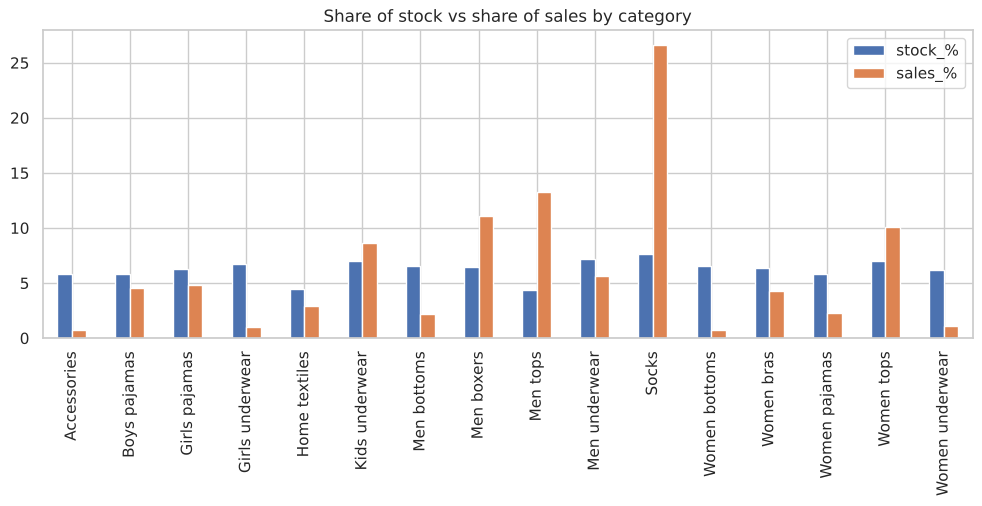

In [47]:
inv[['stock_%', 'sales_%']].plot.bar(figsize=(12, 4), title='Share of stock vs share of sales by category')

In [48]:
stock_value = stock.groupby('year_month').closing_stock_value_EGP.sum()
print('Latest stock value (EGP):', round(stock_value.iloc[-1]))
print('Last 12 months cost of goods sold (EGP):', round((recent.quantity * recent.unit_cost_EGP).sum()))

Latest stock value (EGP): 345965530
Last 12 months cost of goods sold (EGP): 180771929


## 14. Forecast

<div dir='rtl' style='text-align:right'>التنبؤ</div>

In [49]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

series = orders.groupby(orders.order_date.dt.to_period('M')).size()
series = series.iloc[1:-1]
series.index = series.index.to_timestamp()

train = series.iloc[:-12]
test = series.iloc[-12:]

In [50]:
naive = pd.Series(train.iloc[-12:].values, index=test.index)

model = ExponentialSmoothing(train, trend='add', damped_trend=True, seasonal='mul', seasonal_periods=12).fit()
holt = model.forecast(12)

def mape(pred):
    return (abs(pred - test) / test).mean() * 100

print('Same month last year  MAPE:', round(mape(naive), 1), '%')
print('Holt-Winters          MAPE:', round(mape(holt), 1), '%')

Same month last year  MAPE: 9.7 %
Holt-Winters          MAPE: 2.0 %


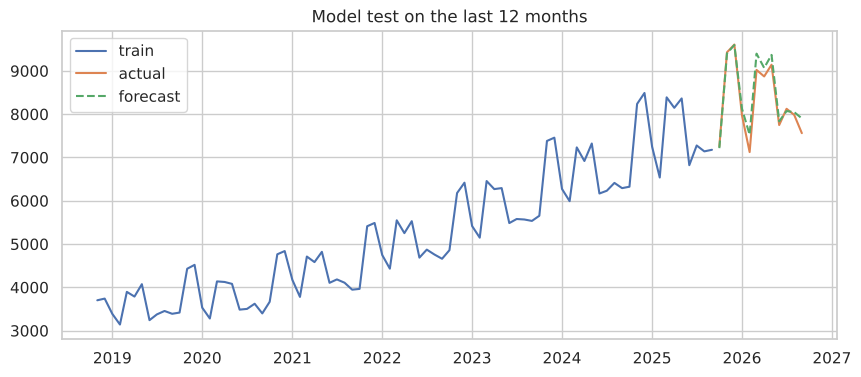

In [51]:
plt.plot(train.index, train, label='train')
plt.plot(test.index, test, label='actual')
plt.plot(holt.index, holt, label='forecast', linestyle='--')
plt.title('Model test on the last 12 months')
plt.legend()

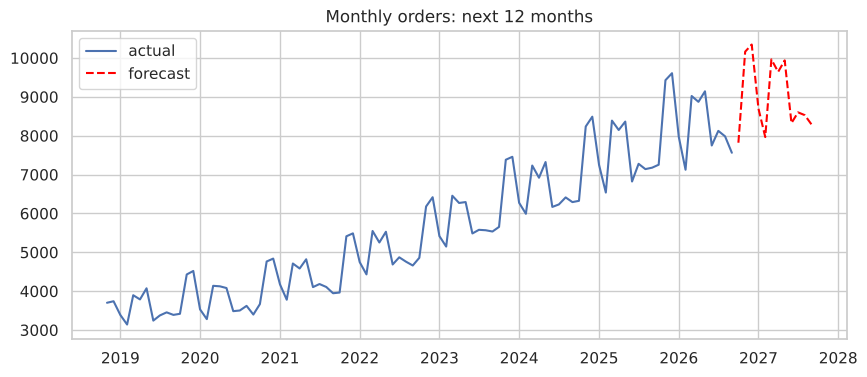

In [52]:
final = ExponentialSmoothing(series, trend='add', damped_trend=True, seasonal='mul', seasonal_periods=12).fit()
future = final.forecast(12)

plt.plot(series.index, series, label='actual')
plt.plot(future.index, future, label='forecast', linestyle='--', color='red')
plt.title('Monthly orders: next 12 months')
plt.legend()

In [53]:
avg_order = orders[orders.year == 2026].net_before_tax_EGP.mean()
forecast = pd.DataFrame({'orders': future.round(0)})
forecast['revenue_EGP'] = forecast.orders * avg_order
forecast

,orders,revenue_EGP
2026-10-01,"7,819.00","23,885,780.91"
2026-11-01,"10,162.00","31,043,267.12"
2026-12-01,"10,346.00","31,605,357.37"
2027-01-01,"8,693.00","26,555,709.61"
2027-02-01,"7,965.00","24,331,787.31"
2027-03-01,"9,963.00","30,435,354.29"
2027-04-01,"9,643.00","29,457,806.02"
2027-05-01,"9,938.00","30,358,983.33"
2027-06-01,"8,324.00","25,428,474.27"
2027-07-01,"8,600.00","26,271,609.65"
